Universidad del Valle de Guatemala  
Departamento de Ciencias de la Computación  
CC3084 - Data Science - sección 40

Integrantes:  
- Cristian Túnchez (231359)
- Dulce Ambrosio (231143)
- Daniel Chet (231177)
- Javier Linares (231135)

# 02. Análisis exploratorio de los datos

**MAP - Charting Student Math Misunderstandings**

En este cuaderno se explora el conjunto limpio producido por `01_carga_y_limpieza.ipynb`. El objetivo no es construir un modelo sino entender los insumos: qué forma tienen los datos, qué tan separables son las clases y qué obstáculos concretos condicionarán el modelado.

El trabajo se organiza de la siguiente manera:

1. **Variables cuantitativas.** Estadística descriptiva, histogramas, diagramas de caja y tratamiento de valores atípicos.
2. **Variables categóricas.** Tablas de frecuencia, tablas de proporciones y gráficos de barras.
3. **Cruces entre variables.** Relaciones entre las variables más importantes, correlaciones y medidas de asociación.
4. **Señal léxica.** Qué palabras distinguen a cada categoría.
5. **Hallazgos y conclusiones.**

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ / "src"))

from utils import cargar, set_estilo

set_estilo()
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 100)

train = cargar("train_limpio")
print("Observaciones:", f"{train.shape[0]:,}", "| Variables:", train.shape[1])

Observaciones: 36,696 | Variables: 24


## 1. Variables cuantitativas

Como se explicó en el cuaderno anterior, el conjunto original no trae ninguna variable numérica. Las cuatro que se analizan aquí fueron derivadas del texto de la explicación:

- `n_caracteres`: longitud del texto.
- `n_palabras`: cantidad de palabras.
- `long_media_palabra`: caracteres por palabra en promedio.
- `n_digitos`: cantidad de cifras numéricas.

### 1.1 Estadística descriptiva

In [2]:
NUM = ["n_caracteres", "n_palabras", "long_media_palabra", "n_digitos"]

descriptiva = train[NUM].describe().T
descriptiva["rango_ic"] = descriptiva["75%"] - descriptiva["25%"]
descriptiva["cv"] = (descriptiva["std"] / descriptiva["mean"]).round(2)
descriptiva["asimetria"] = train[NUM].skew().round(2)
descriptiva["curtosis"] = train[NUM].kurt().round(2)
descriptiva.round(2)

,count,mean,std,min,25%,50%,75%,max,rango_ic,cv,asimetria,curtosis
n_caracteres,36696.0,69.78,38.44,1.0,43.00,60.00,86.00,586.00,43.00,0.55,1.89,6.68
n_palabras,36696.0,15.36,8.12,1.0,10.00,13.00,19.00,177.00,9.00,0.53,1.87,9.06
long_media_palabra,36696.0,4.56,0.67,1.0,4.12,4.54,4.96,15.67,0.84,0.15,0.72,6.50
n_digitos,36696.0,4.72,4.61,0.0,1.00,4.00,7.00,101.00,6.00,0.98,1.63,8.39


### ¿Qué se observa?

Las cuatro variables comparten un mismo perfil: **asimetría positiva** y **curtosis alta**. Esto quiere decir que la mayoría de los valores se concentran en la parte baja y que existe una cola larga hacia la derecha.

El caso más claro es `n_palabras`. La mediana es de 13 palabras y el tercer cuartil de 19, pero el máximo llega a 177. La explicación típica es una sola frase corta, mientras que unas pocas son textos extensos.

`long_media_palabra` es la excepción parcial. Su coeficiente de variación es de apenas 0.15, la más estable de las cuatro, lo que es esperable porque la longitud media de las palabras en inglés varía poco entre textos.

`n_digitos` tiene el coeficiente de variación más alto, cercano a 1. Hay explicaciones sin ninguna cifra y otras con más de cien. Esta variable separa dos formas muy distintas de responder: describir con palabras o mostrar el cálculo.

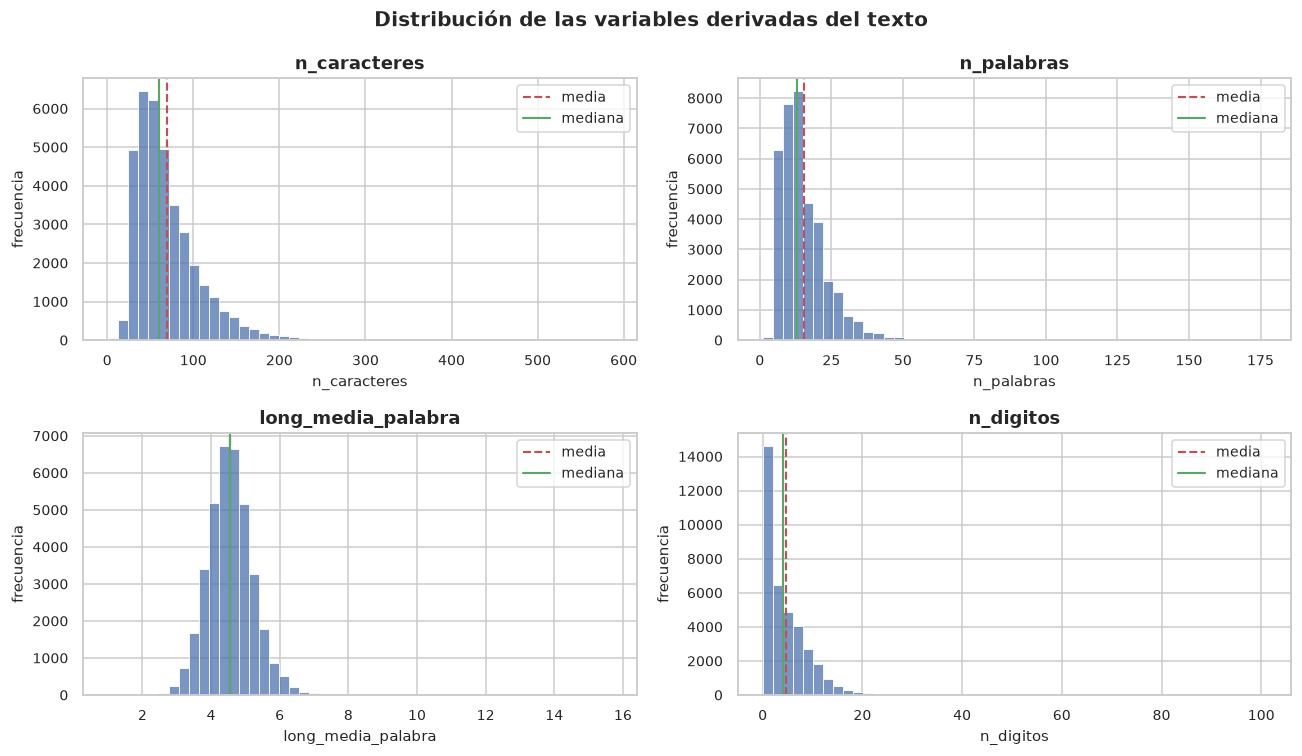

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.ravel(), NUM):
    sns.histplot(train[col], bins=50, ax=ax, color="#4C72B0", edgecolor=None)
    ax.axvline(train[col].mean(), color="#C44E52", ls="--", lw=1.4, label="media")
    ax.axvline(train[col].median(), color="#55A868", ls="-", lw=1.4, label="mediana")
    ax.set_title(col)
    ax.set_ylabel("frecuencia")
    ax.legend()
fig.suptitle("Distribución de las variables derivadas del texto", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

Los histogramas confirman lo anterior. En las tres primeras variables la media queda a la derecha de la mediana (distribución sesgada hacia la derecha). En `n_digitos` se aprecia además un pico pronunciado en cero, correspondiente a las explicaciones puramente verbales.

### 1.2 Valores atípicos

Se identifican los valores atípicos con el criterio del rango intercuartílico, que marca como extremo todo lo que quede a más de 1.5 rangos intercuartílicos de los cuartiles.

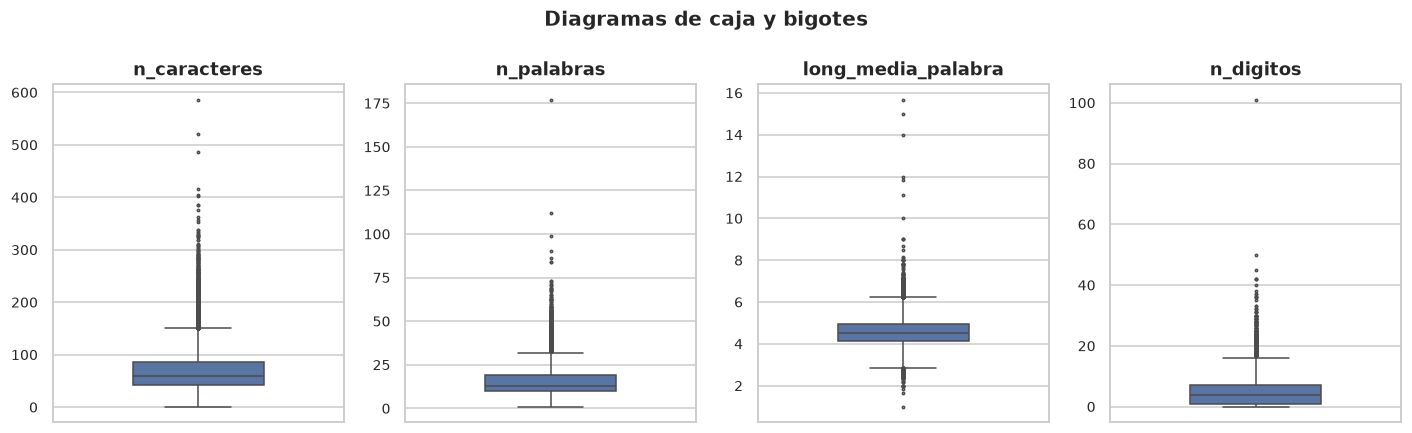

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(13, 4))
for ax, col in zip(axes, NUM):
    sns.boxplot(y=train[col], ax=ax, color="#4C72B0", width=0.45, fliersize=1.5)
    ax.set_title(col)
    ax.set_ylabel("")
fig.suptitle("Diagramas de caja y bigotes", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

In [5]:
filas = []
for col in NUM:
    q1, q3 = train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    bajos = (train[col] < inf).sum()
    altos = (train[col] > sup).sum()
    filas.append({
        "variable": col, "limite_inferior": round(inf, 2), "limite_superior": round(sup, 2),
        "atipicos_bajos": bajos, "atipicos_altos": altos,
        "pct_atipicos": round((bajos + altos) / len(train) * 100, 2),
    })
pd.DataFrame(filas)

,variable,limite_inferior,limite_superior,atipicos_bajos,atipicos_altos,pct_atipicos
0,n_caracteres,-21.50,150.50,0,1556,4.24
1,n_palabras,-3.50,32.50,0,1499,4.08
2,long_media_palabra,2.86,6.22,132,452,1.59
3,n_digitos,-8.00,16.00,0,742,2.02


In [6]:
print("Las cinco explicaciones más cortas:")
print(train.nsmallest(5, "n_caracteres")[["explicacion_limpia", "Category"]].to_string(index=False))
print()
print("La explicación más larga (primeros 260 caracteres):")
print(train.loc[train["n_caracteres"].idxmax(), "explicacion_limpia"][:260])
print()
print("Categoría de las 1,556 explicaciones más largas, en porcentaje:")
largas = train[train["n_caracteres"] > 150]
print((largas["Category"].value_counts(normalize=True) * 100).round(1).to_string())
print()
print("Categoría del total, en porcentaje, para comparar:")
print((train["Category"].value_counts(normalize=True) * 100).round(1).to_string())

Las cinco explicaciones más cortas:
explicacion_limpia      Category
                 d  True_Neither
                ?? False_Neither
                -3  True_Neither
                d.  True_Neither
                b. False_Neither

La explicación más larga (primeros 260 caracteres):
In order to do this, you will have to turn the 5 into a 1 and then times 2 3s and 5 1s together making 10 3d. Then, using your understanding of addition and subtraction as well as working out how many 3's there are in one whole number (that is three), divide t

Categoría de las 1,556 explicaciones más largas, en porcentaje:
Category
True_Correct           67.4
False_Misconception    14.1
True_Neither            8.4
False_Neither           8.2
True_Misconception      1.3
False_Correct           0.7

Categoría del total, en porcentaje, para comparar:
Category
True_Correct           40.3
False_Misconception    25.8
False_Neither          17.8
True_Neither           14.3
True_Misconception      1.1
False_Cor

### ¿Qué se observa y qué se decide?

Los valores atípicos representan entre el 1.6% y el 4.2% de las observaciones según la variable. Al inspeccionarlos se comprueba que **no son errores de registro sino respuestas reales y significativas**.

- En el extremo bajo aparecen respuestas como `d`, `??`, `-3` o `3/9`. Son estudiantes que escribieron la letra de la opción, un signo de duda o el resultado sin justificar nada. Casi todas caen en la categoría `Neither`, que es exactamente lo que esa categoría describe.
- En el extremo alto hay razonamientos largos y elaborados, con errores de ortografía pero con contenido. Al comparar su composición con la del conjunto completo se ve que las explicaciones largas están **sobrerrepresentadas en las categorías `Correct`** y subrepresentadas en `Neither`.

**Decisión:** los valores atípicos **no se eliminan ni se recortan**. Son informativos y su eliminación borraría precisamente la señal que interesa. Para los análisis que lo requieran se usan estadísticos robustos, como la mediana, en lugar de la media.

### 1.3 Relación entre las variables cuantitativas

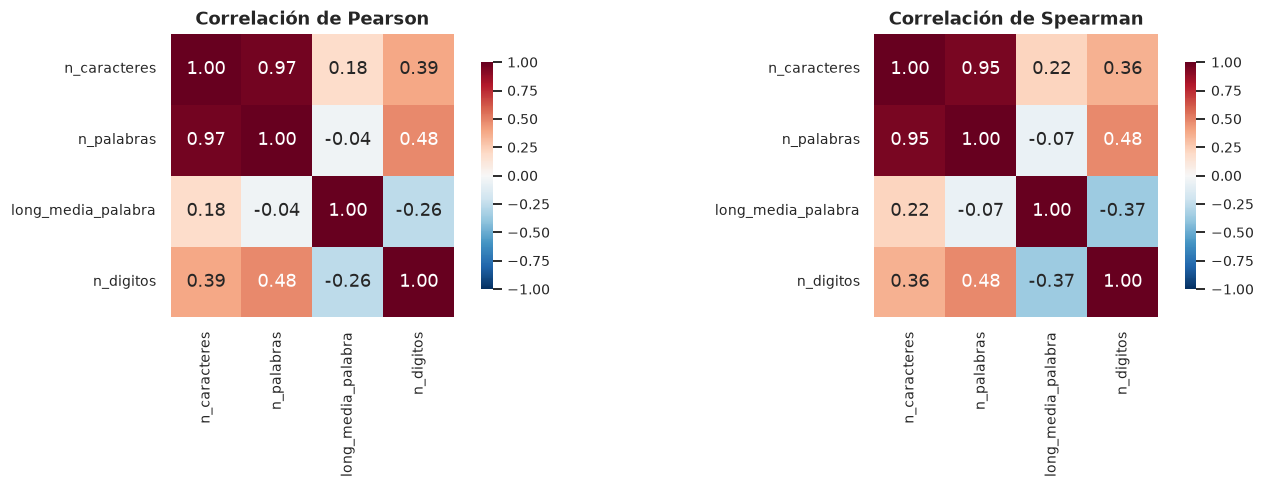

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

corr_p = train[NUM].corr()
sns.heatmap(corr_p, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, ax=axes[0], cbar_kws={"shrink": 0.8})
axes[0].set_title("Correlación de Pearson")

corr_s = train[NUM].corr(method="spearman")
sns.heatmap(corr_s, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, ax=axes[1], cbar_kws={"shrink": 0.8})
axes[1].set_title("Correlación de Spearman")
fig.tight_layout()
plt.show()

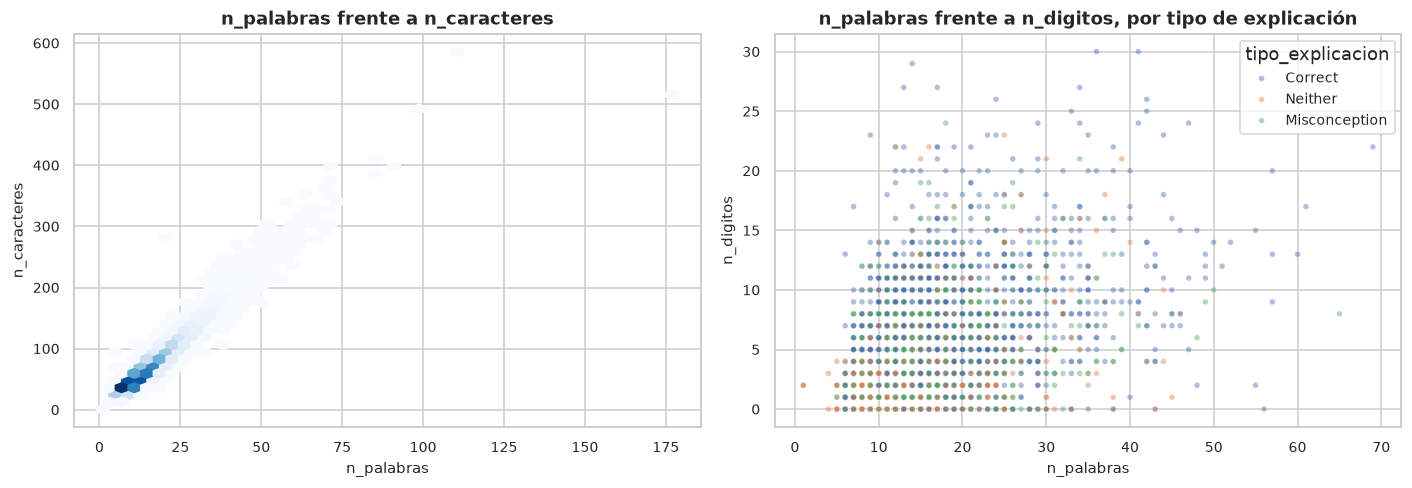

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

axes[0].hexbin(train["n_palabras"], train["n_caracteres"], gridsize=45, cmap="Blues", mincnt=1)
axes[0].set_xlabel("n_palabras"); axes[0].set_ylabel("n_caracteres")
axes[0].set_title("n_palabras frente a n_caracteres")

muestra = train.sample(4000, random_state=42)
sns.scatterplot(data=muestra, x="n_palabras", y="n_digitos", hue="tipo_explicacion",
                alpha=0.45, s=14, ax=axes[1])
axes[1].set_title("n_palabras frente a n_digitos, por tipo de explicación")
axes[1].legend(title="tipo_explicacion", loc="upper right")
fig.tight_layout()
plt.show()

### ¿Qué se observa?

La correlación entre `n_caracteres` y `n_palabras` es de **0.97**, prácticamente perfecta. Esto era esperable, pues las dos miden lo mismo, el largo del texto. Para el modelado conviene conservar solo una de las dos, porque la información que aportan es redundante.

El resto de correlaciones son moderadas y aportan información distinta.

- `n_palabras` y `n_digitos` correlacionan 0.48. Los textos más largos tienden a incluir más cálculo, pero la relación está lejos de ser determinista.
- `long_media_palabra` y `n_digitos` correlacionan **negativamente**, en torno a menos 0.26. Esto tiene sentido, pues las cifras son cadenas cortas, de modo que una explicación cargada de números baja el promedio de caracteres por palabra. Esta variable capta entonces algo que las otras no: el equilibrio entre escribir y calcular.

El gráfico de dispersión muestra además que las explicaciones del tipo `Neither` se concentran en la esquina inferior izquierda, es decir, son cortas y con pocas cifras. Es la primera evidencia visual de que las variables derivadas del texto sí separan, al menos parcialmente, las categorías.

## 2. Variables categóricas

### 2.1 La variable `Category`

Es la variable objetivo principal. Combina dos decisiones: si la opción elegida era correcta y qué revela la explicación.

In [9]:
tabla = train["Category"].value_counts().to_frame("frecuencia")
tabla["proporcion"] = (tabla["frecuencia"] / len(train) * 100).round(2)
tabla["acumulado"] = tabla["proporcion"].cumsum().round(2)
tabla

,frecuencia,proporcion,acumulado
Category,,,
True_Correct,14802,40.34,40.34
False_Misconception,9457,25.77,66.11
False_Neither,6542,17.83,83.94
True_Neither,5265,14.35,98.29
True_Misconception,403,1.10,99.39
False_Correct,227,0.62,100.01


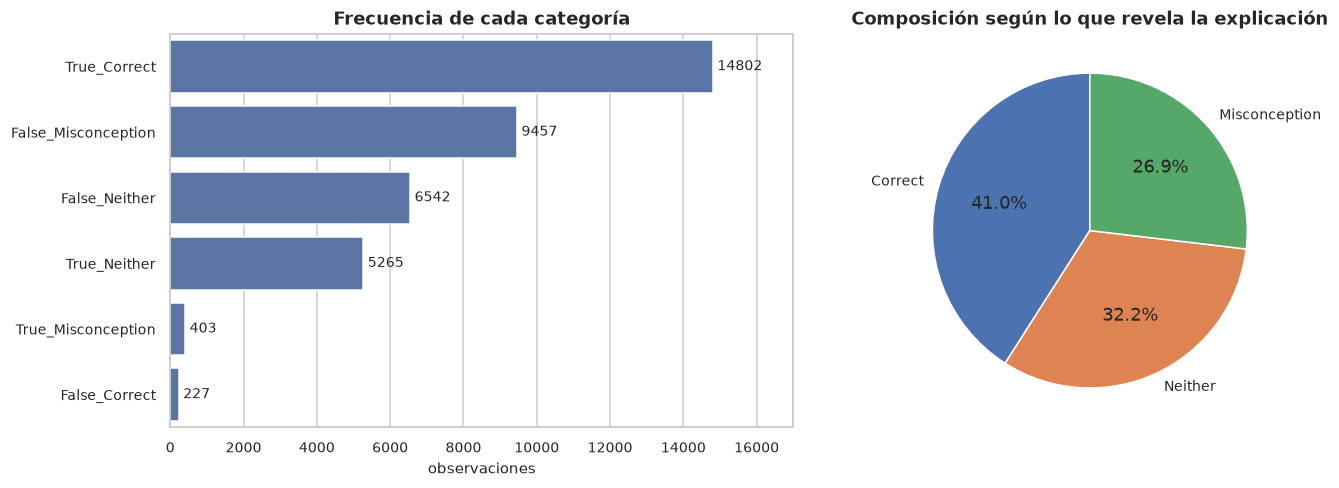

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

orden = train["Category"].value_counts().index
sns.countplot(data=train, y="Category", order=orden, ax=axes[0], color="#4C72B0")
for cont in axes[0].containers:
    axes[0].bar_label(cont, fmt="%d", padding=3, fontsize=9)
axes[0].set_title("Frecuencia de cada categoría")
axes[0].set_xlabel("observaciones"); axes[0].set_ylabel("")
axes[0].set_xlim(0, 17000)

partes = train["tipo_explicacion"].value_counts()
axes[1].pie(partes, labels=partes.index, autopct="%1.1f%%", startangle=90,
            colors=sns.color_palette("deep", 3), wedgeprops={"edgecolor": "white"})
axes[1].set_title("Composición según lo que revela la explicación")
fig.tight_layout()
plt.show()

### ¿Qué se observa?

La distribución está claramente desbalanceada:

- `True_Correct` concentra el **40.34%** de las observaciones. Es el caso normal, el estudiante acierta y explica bien.
- `False_Misconception` aporta el **25.77%**. Es el caso central de la competencia, el estudiante falla y su explicación revela por qué.
- Las dos categorías menos frecuentes son de las más interesantes desde el punto de vista educativo. `True_Misconception` reúne apenas **403 casos, el 1.10%**, y `False_Correct` solo **227 casos, el 0.62%**.

`True_Misconception` merece atención especial. Corresponde al estudiante que marca la opción correcta pero razona mal. Es el caso que ningún sistema basado en el resultado puede detectar, y es también el más escaso. Un modelo entrenado sin cuidado simplemente lo ignorará, porque equivocarse en 403 casos de 36,696 casi no afecta la exactitud global.

### 2.2 La variable `Misconception`

In [11]:
con_error = train[train["misconception"] != "NA"]
frec = con_error["misconception"].value_counts()

tabla_m = frec.to_frame("frecuencia")
tabla_m["pct_sobre_errores"] = (tabla_m["frecuencia"] / len(con_error) * 100).round(2)
tabla_m["pct_sobre_total"] = (tabla_m["frecuencia"] / len(train) * 100).round(2)
tabla_m["acumulado"] = tabla_m["pct_sobre_errores"].cumsum().round(2)

print("Observaciones con error conceptual:", f"{len(con_error):,}",
      f"({len(con_error) / len(train) * 100:.2f} % del total)")
print("Etiquetas distintas:", frec.size)
print("Razón entre la más y la menos frecuente:", round(frec.iloc[0] / frec.iloc[-1], 1), "a 1")
tabla_m.head(12)

Observaciones con error conceptual: 9,860 (26.87 % del total)
Etiquetas distintas: 35
Razón entre la más y la menos frecuente: 242.3 a 1


,frecuencia,pct_sobre_errores,pct_sobre_total,acumulado
misconception,,,,
Incomplete,1454,14.75,3.96,14.75
Additive,929,9.42,2.53,24.17
Duplication,704,7.14,1.92,31.31
Subtraction,620,6.29,1.69,37.60
Positive,566,5.74,1.54,43.34
Wrong_term,558,5.66,1.52,49.00
Irrelevant,497,5.04,1.35,54.04
Wrong_fraction,418,4.24,1.14,58.28
Inversion,414,4.20,1.13,62.48


In [12]:
print("Las ocho etiquetas menos frecuentes:")
tabla_m.tail(8)

Las ocho etiquetas menos frecuentes:


,frecuencia,pct_sobre_errores,pct_sobre_total,acumulado
misconception,,,,
Longer_is_bigger,24,0.24,0.07,98.76
Base_rate,23,0.23,0.06,98.99
Ignores_zeroes,23,0.23,0.06,99.22
Shorter_is_bigger,23,0.23,0.06,99.45
Inverse_operation,21,0.21,0.06,99.66
Certainty,18,0.18,0.05,99.84
Incorrect_equivalent_fraction_addition,9,0.09,0.02,99.93
Wrong_Operation,6,0.06,0.02,99.99


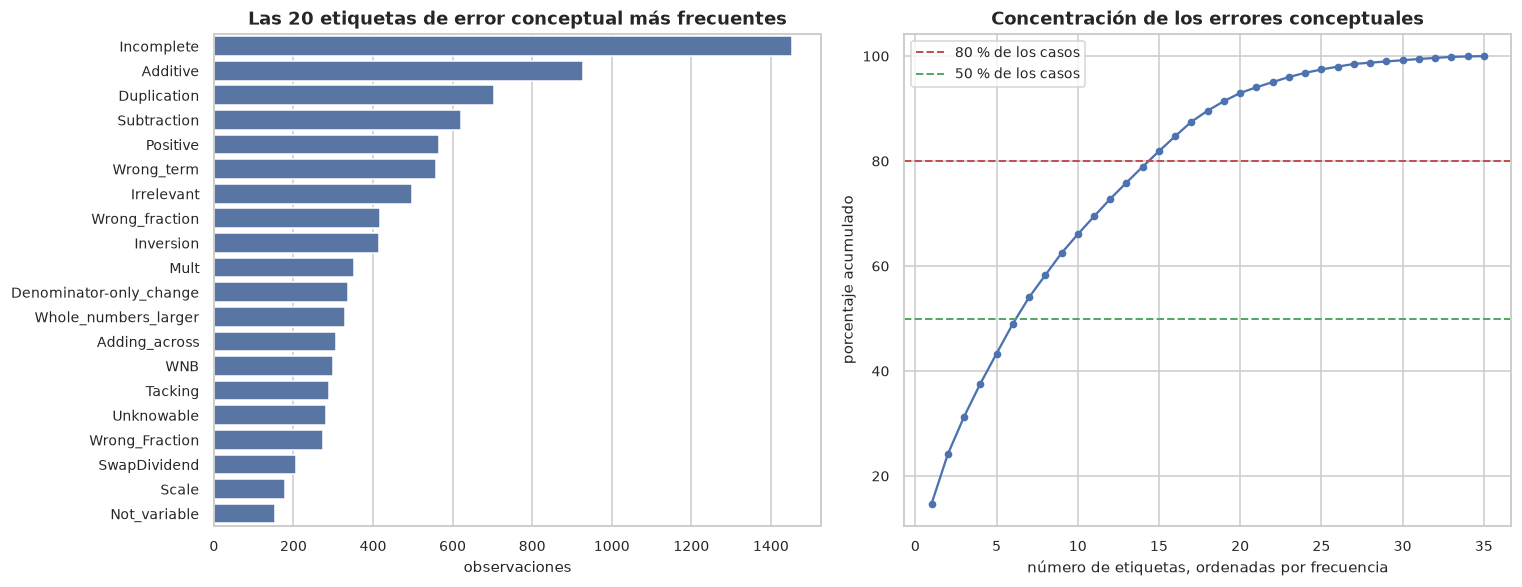

Se necesitan  7 de las 35 etiquetas para cubrir el 50 % de los casos.
Se necesitan 15 de las 35 etiquetas para cubrir el 80 % de los casos.
Se necesitan 19 de las 35 etiquetas para cubrir el 90 % de los casos.


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

top = frec.head(20)
sns.barplot(x=top.values, y=top.index, ax=axes[0], color="#4C72B0")
axes[0].set_title("Las 20 etiquetas de error conceptual más frecuentes")
axes[0].set_xlabel("observaciones"); axes[0].set_ylabel("")

acum = (frec.cumsum() / frec.sum() * 100).values
axes[1].plot(range(1, len(acum) + 1), acum, marker="o", ms=4, color="#4C72B0")
axes[1].axhline(80, color="#C44E52", ls="--", lw=1.3, label="80 % de los casos")
axes[1].axhline(50, color="#55A868", ls="--", lw=1.3, label="50 % de los casos")
axes[1].set_xlabel("número de etiquetas, ordenadas por frecuencia")
axes[1].set_ylabel("porcentaje acumulado")
axes[1].set_title("Concentración de los errores conceptuales")
axes[1].legend()
fig.tight_layout()
plt.show()

for umbral in (50, 80, 90):
    n = int((acum < umbral).sum()) + 1
    print(f"Se necesitan {n:2d} de las 35 etiquetas para cubrir el {umbral} % de los casos.")

### ¿Qué se observa?

El desbalance es severo. Las 9,860 observaciones con error conceptual se reparten entre 35 etiquetas, pero de forma muy desigual: **la etiqueta más frecuente tiene 242 veces más casos que la menos frecuente**.

La curva de concentración lo resume bien: **siete etiquetas bastan para cubrir la mitad de los casos** y **quince cubren el 80%**. Las veinte restantes se reparten el quinto final. Hay etiquetas con menos de diez observaciones en todo el conjunto, como `Wrong_Operation` con seis.

Esto tiene una consecuencia práctica inmediata. Con seis ejemplos no se puede entrenar ni validar de forma fiable una clase. Las opciones son agrupar las etiquetas de cola larga, tratarlas con técnicas específicas para clases raras, o aceptar que el modelo no las aprenderá.

### 2.3 La variable objetivo completa

In [14]:
objetivo = train["objetivo"].value_counts()
print("Combinaciones Category:Misconception distintas:", objetivo.size)
print("Frecuencia máxima:", f"{objetivo.max():,}", "| mínima:", objetivo.min())
print("Combinaciones con menos de 50 observaciones:", int((objetivo < 50).sum()))
print("Combinaciones con menos de 10 observaciones:", int((objetivo < 10).sum()))
print()
print("Las seis más frecuentes:")
print(objetivo.head(6).to_string())
print()
print("Las seis menos frecuentes:")
print(objetivo.tail(6).to_string())

Combinaciones Category:Misconception distintas: 65
Frecuencia máxima: 14,802 | mínima: 1
Combinaciones con menos de 50 observaciones: 32
Combinaciones con menos de 10 observaciones: 24

Las seis más frecuentes:
objetivo
True_Correct:NA                    14802
False_Neither:NA                    6542
True_Neither:NA                     5265
False_Misconception:Incomplete      1446
False_Misconception:Additive         891
False_Misconception:Duplication      698

Las seis menos frecuentes:
objetivo
True_Misconception:Subtraction             2
True_Misconception:Not_variable            1
True_Misconception:Whole_numbers_larger    1
True_Misconception:Adding_across           1
True_Misconception:Longer_is_bigger        1
True_Misconception:Base_rate               1


### ¿Qué se observa?

El problema real no tiene 6 clases sino **65**. De ellas, **32 tienen menos de 50 observaciones** y **24 tienen menos de 10**. Una combinación aparece una sola vez en todo el conjunto.

Esto explica por qué la competencia evalúa con una métrica que admite tres predicciones. Con 65 clases tan desiguales, exigir una única respuesta correcta sería excesivamente estricto.

### 2.4 Las preguntas y las opciones de respuesta

In [15]:
por_pregunta = (
    train.groupby("QuestionId")
    .agg(observaciones=("row_id", "size"),
         tasa_acierto=("respuesta_correcta", "mean"),
         errores_distintos=("misconception", lambda s: s[s != "NA"].nunique()))
    .assign(tasa_acierto=lambda d: (d["tasa_acierto"] * 100).round(1))
    .sort_values("observaciones", ascending=False)
)
por_pregunta

,observaciones,tasa_acierto,errores_distintos
QuestionId,,,
31772,4857,48.3,2
31778,3640,48.4,3
31774,3115,61.6,3
32833,3105,51.6,3
89443,3054,45.6,2
31777,2809,64.0,3
33472,2800,59.0,3
91695,2610,59.3,2
32835,2332,71.8,4


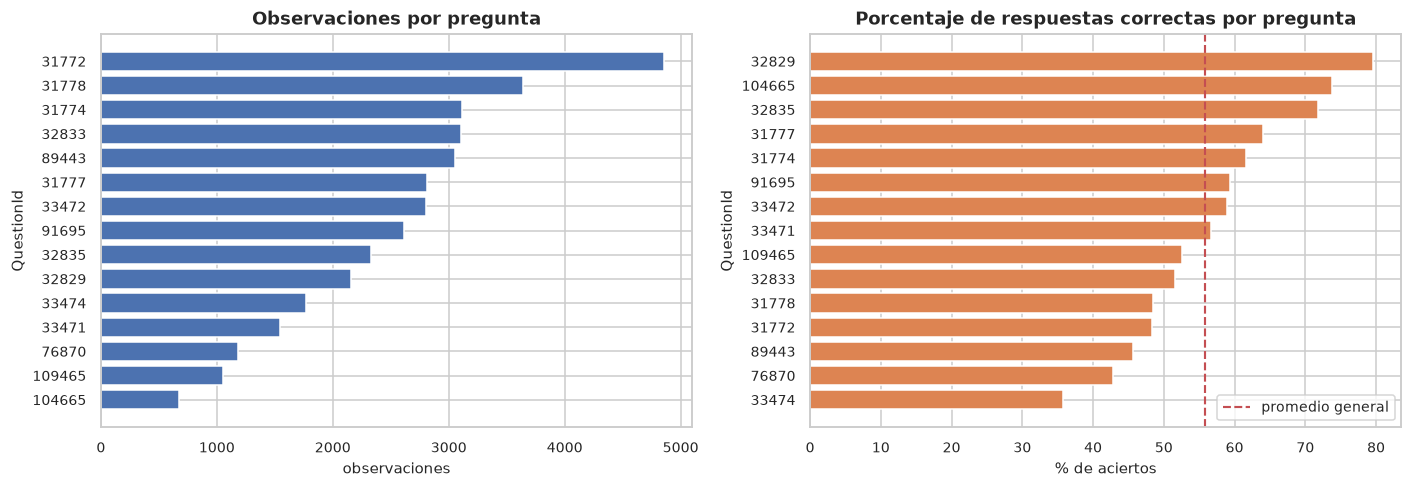

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

datos = por_pregunta.sort_values("observaciones")
axes[0].barh(datos.index.astype(str), datos["observaciones"], color="#4C72B0")
axes[0].set_title("Observaciones por pregunta")
axes[0].set_xlabel("observaciones"); axes[0].set_ylabel("QuestionId")

datos2 = por_pregunta.sort_values("tasa_acierto")
axes[1].barh(datos2.index.astype(str), datos2["tasa_acierto"], color="#DD8452")
axes[1].axvline(train["respuesta_correcta"].mean() * 100, color="#C44E52", ls="--",
                lw=1.4, label="promedio general")
axes[1].set_title("Porcentaje de respuestas correctas por pregunta")
axes[1].set_xlabel("% de aciertos"); axes[1].set_ylabel("QuestionId")
axes[1].legend()
fig.tight_layout()
plt.show()

### ¿Qué se observa?

Las 36,696 observaciones provienen de **solo 15 preguntas**. El número de respuestas por pregunta va de 673 a 4,857.

El conjunto no es una muestra amplia de problemas de matemática, es una muestra muy profunda de quince problemas concretos. La consecuencia se desarrolla en la sección 3.3.

La dificultad varía mucho entre preguntas. La pregunta 33474 la acierta solo el 35.7% de los estudiantes, mientras que la 32829 la acierta el 79.6%. Esa diferencia de más de cuarenta puntos indica que el conjunto cubre un rango amplio de dificultad.